# Desafio de Random Forest · Aula 7.3

Vamos investigar se uma floresta classifica vinhos melhor do que uma árvore sozinha. O modelo aprende a partir de vinhos que já têm classe conhecida, então é um problema de **classificação supervisionada**.

## 1. Carregar e explorar os dados

A base Wine reúne 178 vinhos, 13 medidas químicas e três classes. Vamos conferir a quantidade de exemplos por classe, se faltam valores e a faixa de cada medida. O gráfico mostra duas das medidas. Os modelos vão receber todas as 13.

178 amostras e 13 características
Valores ausentes nas características 0


,Amostras
Classe,
0,59
1,71
2,48


,min,mean,max
alcohol,11.03,13.00,14.83
malic_acid,0.74,2.34,5.80
ash,1.36,2.37,3.23
alcalinity_of_ash,10.60,19.49,30.00
magnesium,70.00,99.74,162.00
total_phenols,0.98,2.30,3.88
flavanoids,0.34,2.03,5.08
nonflavanoid_phenols,0.13,0.36,0.66
proanthocyanins,0.41,1.59,3.58
color_intensity,1.28,5.06,13.00


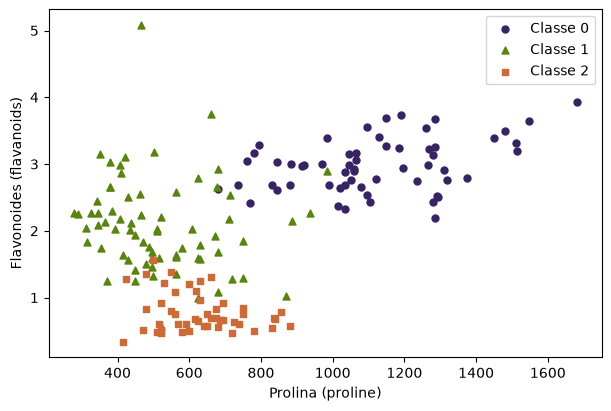

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

vinhos = load_wine(as_frame=True)
X, y = vinhos.data, vinhos.target

print(f"{X.shape[0]} amostras e {X.shape[1]} características")
print(f"Valores ausentes nas características {X.isna().sum().sum()}")
display(y.value_counts().sort_index().rename_axis("Classe").to_frame("Amostras"))
display(X.agg(["min", "mean", "max"]).T.round(2))

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
for classe, cor, marcador in [(0, "#352364", "o"), (1, "#59840D", "^"), (2, "#CE6A36", "s")]:
    grupo = X[y == classe]
    ax.scatter(grupo["proline"], grupo["flavanoids"], c=cor, marker=marcador,
               s=25, label=f"Classe {classe}")
ax.set(xlabel="Prolina (proline)", ylabel="Flavonoides (flavanoids)")
ax.legend()
plt.show()

## 2. Separar treino e teste

Guardamos 25% dos dados para o teste. A separação estratificada mantém aproximadamente a proporção das três classes. A árvore e a floresta recebem a mesma divisão.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y,
)

print(f"Treino com {len(X_train)} vinhos")
print(f"Teste com {len(X_test)} vinhos")

Treino com 133 vinhos
Teste com 45 vinhos


## 3. Treinar e comparar os modelos

Treinamos uma árvore de decisão e uma floresta de 500 árvores. Vamos comparar a acurácia e o F1 macro, que dá o mesmo peso a cada classe. Nas matrizes de confusão, as linhas mostram a classe real, as colunas mostram a previsão e a diagonal mostra os acertos.

,Acurácia treino (%),Acurácia teste (%),F1 macro teste (%)
Modelo,,,
Árvore de decisão,100.0,95.56,95.65
Random Forest,100.0,100.00,100.00


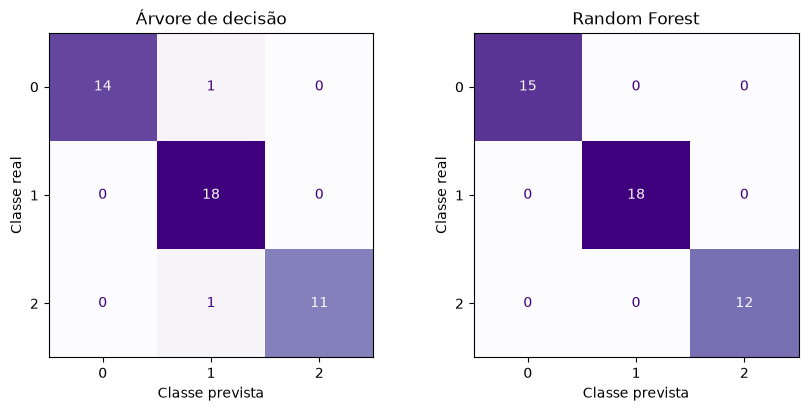

In [3]:
def treinar_floresta(n_arvores=500, profundidade=None):
    modelo = RandomForestClassifier(
        n_estimators=n_arvores,
        max_depth=profundidade,
        bootstrap=True,
        oob_score=True,
        random_state=42,
    )
    return modelo.fit(X_train, y_train)


arvore = DecisionTreeClassifier(random_state=42)
arvore.fit(X_train, y_train)
floresta = treinar_floresta()

resultados = []
fig, eixos = plt.subplots(1, 2, figsize=(8.5, 4), layout="constrained")
for ax, (nome, modelo) in zip(eixos, [("Árvore de decisão", arvore), ("Random Forest", floresta)]):
    previsoes = modelo.predict(X_test)
    resultados.append({
        "Modelo": nome,
        "Acurácia treino (%)": 100 * modelo.score(X_train, y_train),
        "Acurácia teste (%)": 100 * accuracy_score(y_test, previsoes),
        "F1 macro teste (%)": 100 * f1_score(y_test, previsoes, average="macro"),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, previsoes, labels=[0, 1, 2], cmap="Purples", ax=ax, colorbar=False,
        im_kw={"vmin": 0, "vmax": y_test.value_counts().max()},
    )
    ax.set(title=nome, xlabel="Classe prevista", ylabel="Classe real")

comparacao = pd.DataFrame(resultados).set_index("Modelo").round(2)
display(comparacao)
plt.show()

A árvore acertou **43 de 45** vinhos. Ela confundiu um vinho da classe 0 e outro da classe 2 com a classe 1. A floresta acertou **45 de 45** nesta divisão.

## 4. Variar a quantidade de árvores e ler o OOB

Para cada vinho de treino, o OOB combina as previsões das árvores que ficaram sem aquele vinho no sorteio. Assim, podemos comparar configurações usando os dados de treino e manter o teste para a comparação final. Primeiro, variamos a quantidade de árvores com a profundidade livre.

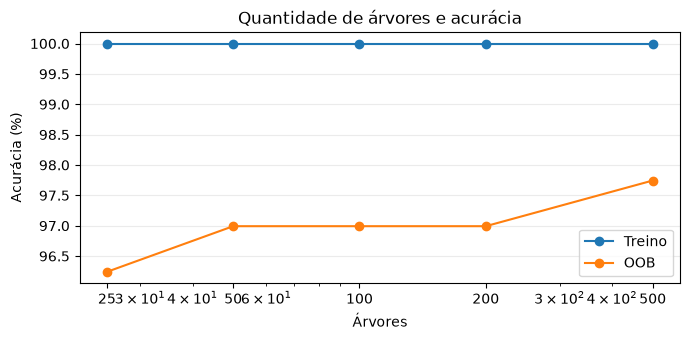

In [4]:
def resumir_floresta(modelo):
    profundidade = modelo.max_depth
    return {
        "Árvores": modelo.n_estimators,
        "Profundidade": "Livre" if profundidade is None else str(profundidade),
        "Treino": 100 * modelo.score(X_train, y_train),
        "OOB": 100 * modelo.oob_score_,
    }


def plotar_acuracias(tabela, coluna, titulo):
    ax = tabela.plot(x=coluna, y=["Treino", "OOB"], marker="o", figsize=(7, 3.5))
    ax.set(title=titulo, ylabel="Acurácia (%)")
    ax.grid(axis="y", alpha=0.25)
    ax.figure.tight_layout()
    return ax


resultado_base = resumir_floresta(floresta)
resultados_n = []
for n in [25, 50, 100, 200]:
    modelo = treinar_floresta(n_arvores=n)
    resultados_n.append(resumir_floresta(modelo))
resultados_n.append(resultado_base)

tabela_n = pd.DataFrame(resultados_n)
ax = plotar_acuracias(tabela_n, "Árvores", "Quantidade de árvores e acurácia")
ax.set_xscale("log")
ax.set_xticks(tabela_n["Árvores"], labels=tabela_n["Árvores"])
plt.show()

O OOB foi de **96,2% com 25 árvores** e **97,7% com 500**. A floresta de 500 árvores teve 97,7% no OOB e 100% no teste. Como o teste tem 45 vinhos, um único erro mudaria a acurácia em cerca de 2,2 pontos percentuais.

## 5. Variar a profundidade

Agora mantemos as 500 árvores e mudamos só o limite de profundidade. Vamos ver até onde permitir mais divisões melhora o desempenho OOB.

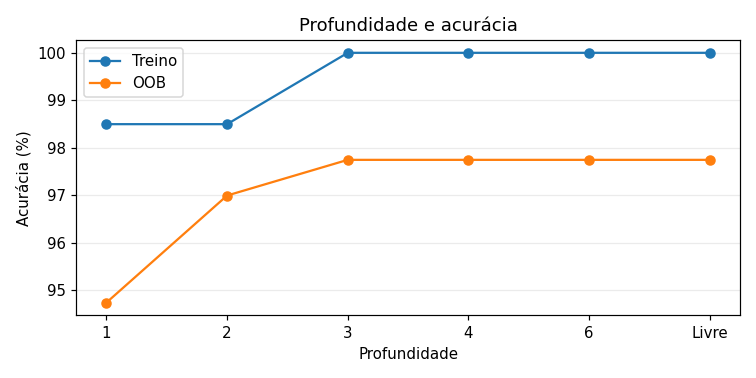

In [5]:
resultados_d = []
for profundidade in [1, 2, 3, 4, 6]:
    modelo = treinar_floresta(profundidade=profundidade)
    resultados_d.append(resumir_floresta(modelo))
resultados_d.append(resultado_base)

tabela_d = pd.DataFrame(resultados_d)
plotar_acuracias(tabela_d, "Profundidade", "Profundidade e acurácia")
plt.show()

Com profundidade 1, o OOB foi de **94,7%**. A profundidade 3 já alcançou **97,7%**, o mesmo valor observado com profundidade 4, 6 e livre.

## 6. Investigar as características mais importantes

A importância por impureza resume quanto cada característica ajudou nas divisões da floresta. Na permutação, embaralhamos uma característica por vez no teste e medimos a queda média na acurácia. Cada gráfico mostra as cinco primeiras de seu ranking.

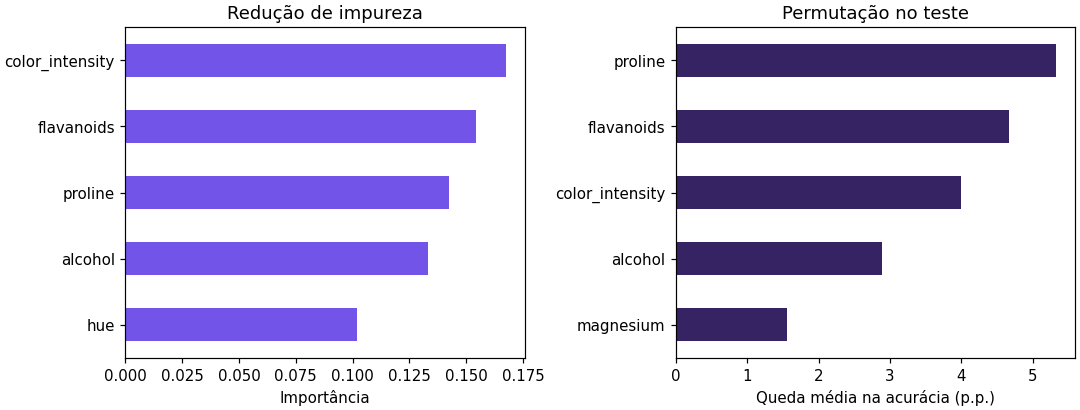

In [6]:
mdi = pd.Series(floresta.feature_importances_, index=X.columns)
perm = permutation_importance(
    floresta, X_test, y_test, scoring="accuracy", n_repeats=10, random_state=42,
)
queda = pd.Series(100 * perm.importances_mean, index=X.columns)

fig, (ax_mdi, ax_perm) = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
mdi.nlargest(5).sort_values().plot.barh(ax=ax_mdi, color="#7255E8")
queda.nlargest(5).sort_values().plot.barh(ax=ax_perm, color="#352364")
ax_mdi.set(title="Redução de impureza", xlabel="Importância")
ax_perm.set(title="Permutação no teste", xlabel="Queda média na acurácia (p.p.)")
plt.show()

A intensidade da cor (`color_intensity`) ficou em primeiro por impureza. A prolina (`proline`) ficou em primeiro por permutação. As duas medidas colocaram intensidade da cor, prolina e flavonoides entre as três características mais importantes.

## Conclusão

Nesta divisão, a Random Forest acertou **dois vinhos a mais** do que a árvore de decisão. O OOB ajudou a enxergar onde os ganhos ficaram pequenos. Com 500 árvores, limitar a profundidade a 3 já deu a mesma acurácia OOB da floresta sem limite.